# AMS · Estatística sobre o Meu Próprio Agente (AO1 — D3)

**Disciplina 3 — Matemática e Estatística para Inteligência Artificial · CEDAGI/UTFPR**

- **Conjunto:** [`d3/ao1/casos-ams-60.csv`](../d3/ao1/casos-ams-60.csv) reúne 60 casos rotulados, com 30 falhas reais e 30 casos normais.
- **Origem dos casos novos:** [`d3/ao1/casos-ams-60.py`](../d3/ao1/casos-ams-60.py) preserva [`d2/lab6/casos-ams.csv`](../d2/lab6/casos-ams.csv) e extrai 30 casos de [`data/raw/ai4i2020.csv`](../data/raw/ai4i2020.csv) com `SEMENTE = 42`, conforme [`d3/ao1/casos-ams-60.md`](../d3/ao1/casos-ams-60.md).
- **Variante A:** [`decidir()`](../src/ams/baseline.py) executa a **linha de base** da D2.
- **Variante B:** [`decidir_variante_b()`](../src/ams/variante_b.py) aplica estresse térmico combinado, desgaste em 2 estágios e confirmação térmica no **estado interno** (`EstadoDaFrota`), detalhados em [`d3/ao1/variante-b.md`](../d3/ao1/variante-b.md).

Este notebook consolida a **Etapa 1** da Atividade Orientada 1 (`AO1`), cobrindo:
1. **Procedência** do conjunto ampliado de avaliação (`60` casos rotulados).
2. **Análise exploratória (`AED`) rigorosa** (distribuições, **valores extremos** por variável com decisão justificada e verificação de faltantes).
3. **Avaliação sobre os mesmos casos** entre a **linha de base** (`Variante A`) e a **Variante B**.
4. **Medição de latência** das invocações do agente com **percentis** `p50` (**mediana**) e `p95`, e análise de **cauda longa**.

> **Escopo:** entrega da **Etapa 1** (antes do Encontro 3), conforme [`d3/ao1/instrucoes-moodle.md`](../d3/ao1/instrucoes-moodle.md) — itens 1 e 2 sem o intervalo.

In [1]:
import json
import math
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path("..").resolve()
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from ams import baseline, variante_b

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

df_60 = pd.read_csv(RAIZ / "d3" / "ao1" / "casos-ams-60.csv")
df_d2 = pd.read_csv(RAIZ / "d2" / "lab6" / "casos-ams.csv")
df_bruto = pd.read_csv(RAIZ / "data" / "raw" / "ai4i2020.csv")
df_acertos = pd.read_csv(RAIZ / "d3" / "ao1" / "acertos.csv")

registros_log = [
    json.loads(linha)
    for linha in (RAIZ / "data" / "logs" / "ams.jsonl").read_text(encoding="utf-8").splitlines()
    if linha.strip()
]
df_logs = pd.DataFrame(registros_log)

print(f"casos-ams-60.csv : {df_60.shape[0]} linhas x {df_60.shape[1]} colunas")
print(f"casos-ams.csv D2 : {df_d2.shape[0]} linhas x {df_d2.shape[1]} colunas")
print(f"ai4i2020.csv     : {df_bruto.shape[0]} linhas x {df_bruto.shape[1]} colunas")
print(f"acertos.csv      : {df_acertos.shape[0]} linhas x {df_acertos.shape[1]} colunas")
print(f"ams.jsonl        : {len(df_logs)} eventos ({df_logs['latencia_ms'].notna().sum()} com latencia_ms)")

casos-ams-60.csv : 60 linhas x 14 colunas
casos-ams.csv D2 : 30 linhas x 14 colunas
ai4i2020.csv     : 10000 linhas x 14 colunas
acertos.csv      : 60 linhas x 2 colunas
ams.jsonl        : 111 eventos (87 com latencia_ms)


---
## 1. Procedência do Conjunto Ampliado (`60` casos)

O conjunto [`d3/ao1/casos-ams-60.csv`](../d3/ao1/casos-ams-60.csv) amplia a amostra da D2 de `30` para `60` casos rotulados e reprodutíveis:
- **Linhas `1` a `30` (D2):** reproduzem [`d2/lab6/casos-ams.csv`](../d2/lab6/casos-ams.csv) com `15` falhas reais e `15` casos normais.
- **Linhas `31` a `60` (D3):** o script [`d3/ao1/casos-ams-60.py`](../d3/ao1/casos-ams-60.py) sorteia `15` falhas reais e `15` casos normais de [`data/raw/ai4i2020.csv`](../data/raw/ai4i2020.csv) com `SEMENTE = 42` e filtros por estrato.

**Atenção à taxa de base (`D3-E2, p. 11–12`):** a base completa de `10.000` registros tem **taxa de base** de falha de `3,39%` (`339/10.000`). Já esta amostra de `60` casos balanceia falhas e normais em `50,0%` (`30/60`). Essa proporção permite comparar as variantes sobre casos de fronteira, mas não estima a prevalência real da planta.

In [2]:
df_proc = df_60.copy()
df_proc["bloco"] = np.where(df_proc.index < 30, "1. D2 (original)", "2. D3 (novo)")
modos = ["TWF", "HDF", "PWF", "OSF", "RNF"]
df_proc["soma_modos"] = df_proc[modos].sum(axis=1)

resumo_blocos = df_proc.groupby("bloco").agg(
    casos=("UDI", "count"),
    falhas=("Machine failure", "sum"),
    normais=("Machine failure", lambda s: int((s == 0).sum())),
    tipo_L=("Type", lambda s: int((s == "L").sum())),
    tipo_M=("Type", lambda s: int((s == "M").sum())),
    tipo_H=("Type", lambda s: int((s == "H").sum())),
)
display(resumo_blocos)

assert list(df_60["UDI"].iloc[:30]) == list(df_d2["UDI"]), "Primeiros 30 UDIs devem coincidir com D2."
taxa_bruta = df_bruto["Machine failure"].mean() * 100
taxa_60 = df_60["Machine failure"].mean() * 100
print(f"Taxa de base real (ai4i2020.csv): {taxa_bruta:.2f}% ({int(df_bruto['Machine failure'].sum())}/{len(df_bruto)})")
print(f"Proporção na amostra pareada (60): {taxa_60:.2f}% ({int(df_60['Machine failure'].sum())}/{len(df_60)})")

,casos,falhas,normais,tipo_L,tipo_M,tipo_H
bloco,,,,,,
1. D2 (original),30,15,15,14,11,5
2. D3 (novo),30,15,15,18,9,3


Taxa de base real (ai4i2020.csv): 3.39% (339/10000)
Proporção na amostra pareada (60): 50.00% (30/60)


---
## 2. Análise Exploratória (`AED`) Rigorosa do Conjunto Ampliado

O código abaixo calcula as medidas dos `5` sensores e dos `6` indicadores binários nos `60` casos. A tabela lista **média**, **mediana** (`p50`), **desvio padrão** (`ddof=1`), **amplitude interquartil** (`AIQ = Q3 - Q1`), faltantes e **valores extremos** pela **regra da interquartil** (`[Q1 - 1,5·AIQ; Q3 + 1,5·AIQ]`).

In [3]:
vars_sensores = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
vars_binarias = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
vars_analise = vars_sensores + vars_binarias

def tabela_rigor(df: pd.DataFrame, colunas: list[str]) -> pd.DataFrame:
    linhas = []
    for col in colunas:
        serie = df[col].astype(float)
        faltantes = int(serie.isna().sum())
        validos = serie.dropna()
        q1, q3 = np.percentile(validos, [25, 75])
        aiq = float(q3 - q1)
        lim_inf = float(q1 - 1.5 * aiq)
        lim_sup = float(q3 + 1.5 * aiq)
        n_extremos = int(((validos < lim_inf) | (validos > lim_sup)).sum())
        linhas.append({
            "variavel": col,
            "n": len(validos),
            "faltantes": faltantes,
            "media": round(float(validos.mean()), 4),
            "mediana": round(float(validos.median()), 4),
            "desvio": round(float(validos.std(ddof=1)), 4),
            "Q1": round(float(q1), 4),
            "Q3": round(float(q3), 4),
            "AIQ": round(aiq, 4),
            "min": round(float(validos.min()), 4),
            "max": round(float(validos.max()), 4),
            "extremos_1_5_AIQ": n_extremos,
        })
    return pd.DataFrame(linhas)

medidas_60 = tabela_rigor(df_60, vars_analise)
medidas_bruto = tabela_rigor(df_bruto, vars_analise)

print("=== Medidas nos 60 casos (AO1) ===")
display(medidas_60)
print(f"Total de valores extremos marcados nos 60 casos: {int(medidas_60['extremos_1_5_AIQ'].sum())}")
print(f"Total de valores extremos no conjunto completo (10.000 linhas, Lab 3): {int(medidas_bruto['extremos_1_5_AIQ'].sum())}")

=== Medidas nos 60 casos (AO1) ===


,variavel,n,faltantes,media,mediana,desvio,Q1,Q3,AIQ,min,max,extremos_1_5_AIQ
0,Air temperature [K],60,0,299.7283,298.90,2.1079,298.375,301.900,3.525,296.3,304.3,0
1,Process temperature [K],60,0,309.5667,309.10,1.3922,308.675,310.425,1.750,307.2,313.4,1
2,Rotational speed [rpm],60,0,1492.6167,1437.50,230.8651,1373.500,1549.500,176.000,1243.0,2861.0,4
3,Torque [Nm],60,0,45.4717,45.15,13.6238,36.700,54.950,18.250,4.6,74.5,1
4,Tool wear [min],60,0,132.4833,149.00,71.4858,60.250,196.500,136.250,0.0,234.0,0
5,Machine failure,60,0,0.5000,0.50,0.5042,0.000,1.000,1.000,0.0,1.0,0
6,TWF,60,0,0.1000,0.00,0.3025,0.000,0.000,0.000,0.0,1.0,6
7,HDF,60,0,0.0833,0.00,0.2787,0.000,0.000,0.000,0.0,1.0,5
8,PWF,60,0,0.1667,0.00,0.3758,0.000,0.000,0.000,0.0,1.0,10
9,OSF,60,0,0.1333,0.00,0.3428,0.000,0.000,0.000,0.0,1.0,8


Total de valores extremos marcados nos 60 casos: 36
Total de valores extremos no conjunto completo (10.000 linhas, Lab 3): 1199


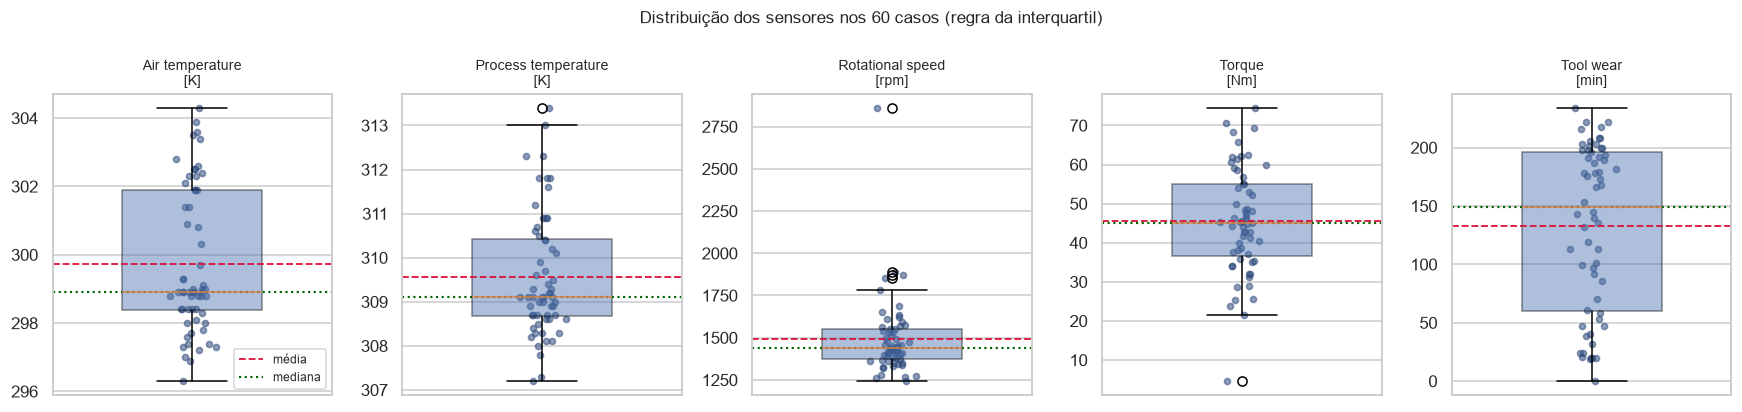

In [4]:
fig, eixos = plt.subplots(1, 5, figsize=(16, 3.8))
for eixo, col in zip(eixos, vars_sensores):
    dados = df_60[col]
    eixo.boxplot(dados, orientation="vertical", widths=0.5, patch_artist=True,
                 boxprops={"facecolor": "#4c72b0", "alpha": 0.45})
    eixo.scatter(np.ones(len(dados)) + np.random.default_rng(42).normal(0, 0.04, len(dados)),
                 dados, alpha=0.55, s=16, color="#2f4b7c")
    eixo.axhline(dados.mean(), color="crimson", linestyle="--", linewidth=1.2, label="média")
    eixo.axhline(dados.median(), color="darkgreen", linestyle=":", linewidth=1.4, label="mediana")
    eixo.set_title(col.replace(" [", "\n["), fontsize=9)
    eixo.set_xticks([])
eixos[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Distribuição dos sensores nos 60 casos (regra da interquartil)", fontsize=11)
plt.tight_layout()
plt.show()

### Decisões

**1. Distribuições das variáveis relevantes (`60` casos da `AO1`):**
- **`Air temperature [K]`:** quase simétrica em torno do centro (`média = 299,73 K`, `mediana / p50 = 298,90 K`, `desvio padrão = 2,11 K`, `AIQ = 3,525 K`, intervalo de `296,3` a `304,3 K`).
- **`Process temperature [K]`:** concentrada e levemente esticada para cima (`média = 309,57 K`, `p50 = 309,10 K`, `desvio padrão = 1,39 K`, `AIQ = 1,75 K`, de `307,2` a `313,4 K`).
- **`Rotational speed [rpm]`:** **distribuição assimétrica** à direita (`média = 1.492,62 rpm`, `p50 = 1.437,50 rpm`, `desvio padrão = 230,87 rpm`, `AIQ = 176,0 rpm`), com cauda até `2.861 rpm`.
- **`Torque [Nm]`:** simétrica no centro (`média = 45,47 Nm`, `p50 = 45,15 Nm`, `desvio padrão = 13,62 Nm`, `AIQ = 18,25 Nm`), com variação de `4,6` a `74,5 Nm`.
- **`Tool wear [min]`:** **distribuição assimétrica** espalhada (`média = 132,48 min`, `p50 = 149,00 min`, `desvio padrão = 71,49 min`, `AIQ = 136,25 min`, de `0` a `234 min`), pois inclui estratos de desgaste alto para testes de fronteira.
- **`Machine failure` e modos (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`):** o desfecho soma `50,0%` (`30/60`), enquanto os `5` modos individuais são raros (`1,7%` a `16,7%`).

**2. Valores extremos — decisão variável por variável (`regra da interquartil`, `D3-E2, p. 8`):**

| Variável | Extremos (`60` casos) | Decisão | Por quê e o que muda |
|---|---|---|---|
| `Air temperature [K]` | `0` | Ficam todos | Não há ponto fora de `[293,09; 307,19] K`. |
| `Process temperature [K]` | `1` (`UDI 5165`, `313,4 K`, normal) | Fica | Operação real em regime quente sem falha. A remoção reduziria a variabilidade térmica real. |
| `Rotational speed [rpm]` | `4` (`UDI 51` = `2.861` `PWF`; `UDI 9175` = `1.871` `TWF`; `UDI 4159` = `1.889` e `UDI 6574` = `1.855` normais) | Ficam todos | Rotações altas reais causam ou acompanham falhas. A remoção apagaria casos críticos da avaliação. |
| `Torque [Nm]` | `1` (`UDI 51`, `4,6 Nm`, `PWF`) | Fica | Complementa a rotação extrema (`2.861 rpm`) na falha de potência. Exige **mediana** (`p50`), **AIQ** e perda resistente (**erro absoluto** ou **perda de Huber**, `D3-E2, p. 5–6, 8`). |
| `Tool wear [min]` | `0` | Ficam todos | Não há ponto fora de `[-144,12; 400,88] min`. |
| `Machine failure` | `0` | Ficam todos | Conjunto balanceado (`Q1 = 0`, `Q3 = 1`, `AIQ = 1`). |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | `30` (`TWF=6`, `HDF=5`, `PWF=10`, `OSF=8`, `RNF=1`) | Ficam todos | Como `Q1 = Q3 = 0` e `AIQ = 0`, a regra marca toda falha (`1`) como extremo. A remoção destruiria o conjunto de testes. |

Os `60` casos somam `36` valores extremos (`100%` mantidos). O mesmo critério preserva os `1.199` valores extremos dos `10.000` registros (Lab 3).

**3. Valores faltantes e hipótese de mecanismo (`D3-E2, p. 8–9`; `D3-AO1, p. 2`):**
- **Contagem observada:** há `0` células faltantes nas `14` variáveis dos `60` casos e nos `10.000` registros.
- **Mecanismos da apostila e ações autorizadas:**
  - **Perdido ao acaso (`MCAR`):** a falta não depende de nada; descartar linhas incompletas não enviesa.
  - **Perdido condicionalmente (`MAR`):** a falta depende de outra variável observada; a modelagem corrige essa dependência.
  - **Perdido por causa do próprio valor (`MNAR`):** o valor ausente depende dele próprio (ex.: sensor que satura); não existe correção estatística e o projeto declara o problema.
- **Decisão:** não há faltantes. Nenhuma imputação ou descarte se aplica, o que evita o **preenchimento com a média** e sua falsa redução de variância.

---
## 3. Avaliação Pareada: Linha de Base (`Variante A`) vs. Variante B

No [`agent-spec.md`](../agent-spec.md), a **medida de desempenho** (`Performance` do PEAS) une a **métrica primária** (`Taxa de Captura de Falhas`) e o contrapeso de falsos positivos. Conforme `D3-AO1` (p. 1–2), executamos a **linha de base** ([`src/ams/baseline.py`](../src/ams/baseline.py)) e a **Variante B** ([`src/ams/variante_b.py`](../src/ams/variante_b.py)) nos mesmos `60` casos, na mesma ordem. O comando `npm run d3:ao1:variante-b` grava `0` ou `1` por caso em [`d3/ao1/acertos.csv`](../d3/ao1/acertos.csv), e a célula abaixo confere essa saída. Veja as regras em [`d3/ao1/variante-b.md`](../d3/ao1/variante-b.md) e os `7` casos divergentes em [`d3/ao1/variante-b-comparacao.md`](../d3/ao1/variante-b-comparacao.md).

In [5]:
caminho_60 = RAIZ / "d3" / "ao1" / "casos-ams-60.csv"
res_a = baseline.medir(caminho_60, decidir_fn=baseline.decidir)
res_b = baseline.medir(caminho_60, decidir_fn=variante_b.decidir_variante_b)
pares = variante_b.avaliar_pareado(caminho_60)
df_pares = pd.DataFrame(pares)

assert list(df_pares["variante_a"]) == list(df_acertos["variante_a"]), "Divergência com acertos.csv (A)."
assert list(df_pares["variante_b"]) == list(df_acertos["variante_b"]), "Divergência com acertos.csv (B)."

tabela_metricas = pd.DataFrame([
    {
        "versao": "Linha de base (Variante A)",
        "acertos_60": res_a["acertos"],
        "taxa_acerto_pct": round(res_a["valor"] * 100, 1),
        "recall_falhas": f"{res_a['falhas_capturadas']}/{res_a['total_falhas_reais']} ({res_a['recall']*100:.1f}%)",
        "falsos_positivos": f"{res_a['falsos_positivos']}/{res_a['total_saudaveis']} ({res_a['taxa_fp']*100:.1f}%)",
    },
    {
        "versao": "Variante B",
        "acertos_60": res_b["acertos"],
        "taxa_acerto_pct": round(res_b["valor"] * 100, 1),
        "recall_falhas": f"{res_b['falhas_capturadas']}/{res_b['total_falhas_reais']} ({res_b['recall']*100:.1f}%)",
        "falsos_positivos": f"{res_b['falsos_positivos']}/{res_b['total_saudaveis']} ({res_b['taxa_fp']*100:.1f}%)",
    },
])
display(tabela_metricas)

a1_b1 = int(((df_pares["variante_a"] == 1) & (df_pares["variante_b"] == 1)).sum())
a1_b0 = int(((df_pares["variante_a"] == 1) & (df_pares["variante_b"] == 0)).sum())
a0_b1 = int(((df_pares["variante_a"] == 0) & (df_pares["variante_b"] == 1)).sum())
a0_b0 = int(((df_pares["variante_a"] == 0) & (df_pares["variante_b"] == 0)).sum())

cruzamento = pd.DataFrame(
    [[a1_b1, a1_b0], [a0_b1, a0_b0]],
    index=["Linha de base acertou (1)", "Linha de base errou (0)"],
    columns=["Variante B acertou (1)", "Variante B errou (0)"],
)
print("=== Cruzamento de acertos nos 60 casos ===")
display(cruzamento)

divergentes = df_pares[df_pares["variante_a"] != df_pares["variante_b"]][
    ["id_caso", "falha_real", "decisao_a", "decisao_b", "variante_a", "variante_b"]
]
print(f"Casos com divergência entre A e B: {len(divergentes)} (7 a favor de B, 0 a favor de A)")
display(divergentes)

,versao,acertos_60,taxa_acerto_pct,recall_falhas,falsos_positivos
0,Linha de base (Variante A),49,81.7,25/30 (83.3%),6/30 (20.0%)
1,Variante B,56,93.3,27/30 (90.0%),1/30 (3.3%)


=== Cruzamento de acertos nos 60 casos ===


,Variante B acertou (1),Variante B errou (0)
Linha de base acertou (1),49,0
Linha de base errou (0),7,4


Casos com divergência entre A e B: 7 (7 a favor de B, 0 a favor de A)


,id_caso,falha_real,decisao_a,decisao_b,variante_a,variante_b
8,UDI-72,0,"(medio, True)","(baixo, False)",0,1
9,UDI-73,0,"(medio, True)","(baixo, False)",0,1
10,UDI-74,0,"(alto, True)","(baixo, False)",0,1
16,UDI-157,0,"(alto, True)","(baixo, False)",0,1
26,UDI-1241,0,"(medio, True)","(baixo, False)",0,1
47,UDI-4685,1,"(baixo, False)","(alto, True)",0,1
53,UDI-5537,1,"(baixo, False)","(alto, True)",0,1


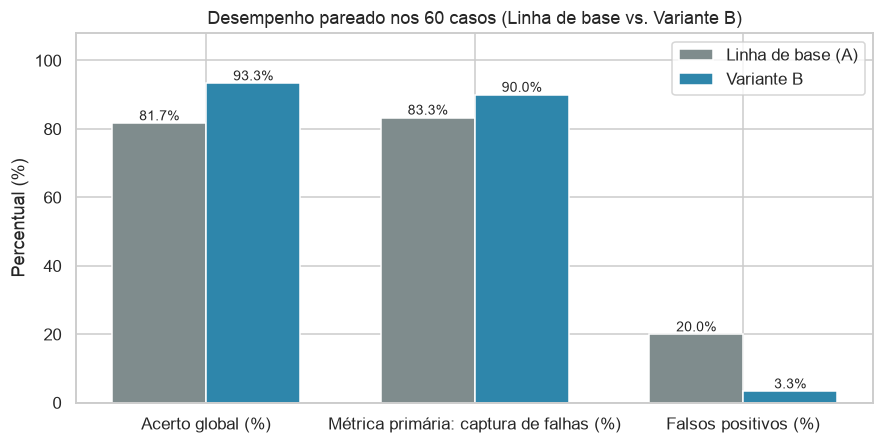

In [6]:
metricas_nomes = ["Acerto global (%)", "Métrica primária: captura de falhas (%)", "Falsos positivos (%)"]
vals_a = [res_a["valor"] * 100, res_a["recall"] * 100, res_a["taxa_fp"] * 100]
vals_b = [res_b["valor"] * 100, res_b["recall"] * 100, res_b["taxa_fp"] * 100]

x = np.arange(len(metricas_nomes))
largura = 0.35
fig, eixo = plt.subplots(figsize=(8.2, 4.2))
b1 = eixo.bar(x - largura / 2, vals_a, largura, label="Linha de base (A)", color="#7f8c8d")
b2 = eixo.bar(x + largura / 2, vals_b, largura, label="Variante B", color="#2e86ab")

for barras in (b1, b2):
    for barra in barras:
        h = barra.get_height()
        eixo.annotate(f"{h:.1f}%", (barra.get_x() + barra.get_width() / 2, h),
                      ha="center", va="bottom", fontsize=9)

eixo.set_xticks(x)
eixo.set_xticklabels(metricas_nomes)
eixo.set_ylim(0, 108)
eixo.set_ylabel("Percentual (%)")
eixo.set_title("Desempenho pareado nos 60 casos (Linha de base vs. Variante B)")
eixo.legend()
plt.tight_layout()
plt.show()

Nos `60` casos avaliados lado a lado, a diferença observada é de `+7` casos (`+11,7` pontos percentuais), com `7` divergências a favor da **Variante B** (`7` a `0`). Conforme `D3-AO1` (p. 1), apenas diferenças acima de `10` a `12` pontos percentuais se distinguem do acaso em `60` casos. Como `+11,7` pontos percentuais cai nessa fronteira, os números desta etapa ainda não confirmam se o ganho é real ou acaso da amostra.

---
## 4. Medição de Latência (`p50`, `p95` e Cauda Longa)

Medimos a latência a partir das duas fontes reais do projeto:
1. **Invocações do agente com modelo de linguagem (`LLM`) em [`data/logs/ams.jsonl`](../data/logs/ams.jsonl):** separamos as `51` chamadas online reais das `36` chamadas simuladas offline.
2. **Camada determinística local:** cronometramos `decidir()` e `decidir_variante_b()` em `50` rodadas sobre os `60` casos de [`d3/ao1/casos-ams-60.csv`](../d3/ao1/casos-ams-60.csv) (`3.000` decisões em `µs`).

=== Latência das invocações registradas em data/logs/ams.jsonl (ms) ===


,origem,n,min,p50,media,p95,max
0,API / LLM online (ams.jsonl),51,1063.0,3292.0,5891.700,21497.50,30363.0
1,Chamadas simuladas offline (ams.jsonl),36,0.0,0.0,0.056,0.25,1.0


=== Latência da camada determinística local (50 rodadas x 60 casos, em µs) ===


,origem,n,min,p50,media,p95,max
0,Linha de base determinística (50 x 60 casos),3000,0.4,0.7,0.8,1.3,4.8
1,Variante B determinística (50 x 60 casos),3000,0.5,0.9,0.9,1.5,55.1


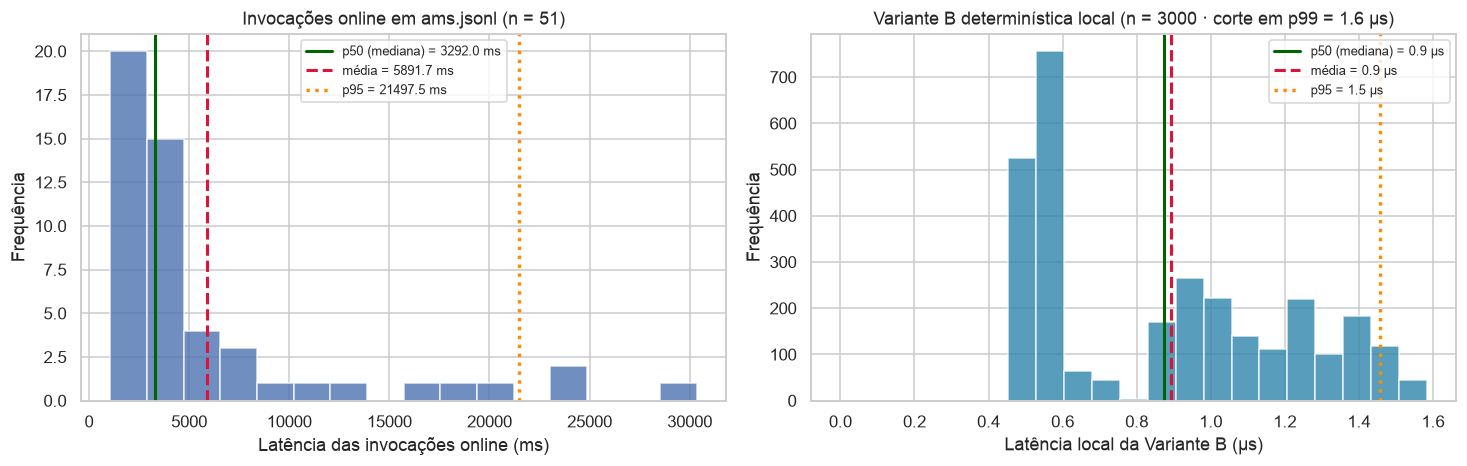

In [7]:
logs_lat = df_logs[df_logs["latencia_ms"].notna()].copy()
lat_online = logs_lat[logs_lat["origem"] == "online"]["latencia_ms"].astype(float).to_numpy()
lat_offline = logs_lat[logs_lat["origem"] == "offline"]["latencia_ms"].astype(float).to_numpy()

def resumo_latencia(nome: str, arr: np.ndarray, unidade: int = 3) -> dict:
    return {
        "origem": nome,
        "n": len(arr),
        "min": round(float(np.min(arr)), unidade),
        "p50": round(float(np.percentile(arr, 50)), unidade),
        "media": round(float(np.mean(arr)), unidade),
        "p95": round(float(np.percentile(arr, 95)), unidade),
        "max": round(float(np.max(arr)), unidade),
    }

df_lat_logs = pd.DataFrame([
    resumo_latencia("API / LLM online (ams.jsonl)", lat_online, unidade=1),
    resumo_latencia("Chamadas simuladas offline (ams.jsonl)", lat_offline, unidade=3),
])
print("=== Latência das invocações registradas em data/logs/ams.jsonl (ms) ===")
display(df_lat_logs)

# Cronometragem determinística local em 50 rodadas (3.000 decisões), em microssegundos (µs)
casos_dict = baseline.carregar_casos(caminho_60)
tempos_a_us, tempos_b_us = [], []
for _ in range(50):
    estado_a, estado_b = baseline.EstadoDaFrota(), baseline.EstadoDaFrota()
    for reg in casos_dict:
        t0 = time.perf_counter()
        baseline.decidir(reg, estado_a)
        tempos_a_us.append((time.perf_counter() - t0) * 1_000_000.0)
        estado_a.registrar_desfecho(reg)

        t0 = time.perf_counter()
        variante_b.decidir_variante_b(reg, estado_b)
        tempos_b_us.append((time.perf_counter() - t0) * 1_000_000.0)
        estado_b.registrar_desfecho(reg)

arr_a = np.array(tempos_a_us)
arr_b = np.array(tempos_b_us)

df_lat_det = pd.DataFrame([
    resumo_latencia("Linha de base determinística (50 x 60 casos)", arr_a, unidade=1),
    resumo_latencia("Variante B determinística (50 x 60 casos)", arr_b, unidade=1),
])
print("=== Latência da camada determinística local (50 rodadas x 60 casos, em µs) ===")
display(df_lat_det)

p50_on = float(np.percentile(lat_online, 50))
media_on = float(np.mean(lat_online))
p95_on = float(np.percentile(lat_online, 95))

p50_b, media_b, p95_b = float(np.percentile(arr_b, 50)), float(np.mean(arr_b)), float(np.percentile(arr_b, 95))
lim_b = float(np.percentile(arr_b, 99))

fig, (eixo_on, eixo_det) = plt.subplots(1, 2, figsize=(13.5, 4.4))

# Painel esquerdo: API / LLM online (ms)
eixo_on.hist(lat_online, bins=16, color="#4c72b0", edgecolor="white", alpha=0.8)
eixo_on.axvline(p50_on, color="darkgreen", linestyle="-", linewidth=2, label=f"p50 (mediana) = {p50_on:.1f} ms")
eixo_on.axvline(media_on, color="crimson", linestyle="--", linewidth=2, label=f"média = {media_on:.1f} ms")
eixo_on.axvline(p95_on, color="darkorange", linestyle=":", linewidth=2.2, label=f"p95 = {p95_on:.1f} ms")
eixo_on.set_xlabel("Latência das invocações online (ms)")
eixo_on.set_ylabel("Frequência")
eixo_on.set_title(f"Invocações online em ams.jsonl (n = {len(lat_online)})")
eixo_on.legend(fontsize=8.5)

# Painel direito: Variante B determinística local (µs)
bins_b = np.linspace(0.0, lim_b, 22)
eixo_det.hist(arr_b[arr_b <= lim_b], bins=bins_b, color="#2e86ab", edgecolor="white", alpha=0.8)
eixo_det.axvline(p50_b, color="darkgreen", linestyle="-", linewidth=2, label=f"p50 (mediana) = {p50_b:.1f} µs")
eixo_det.axvline(media_b, color="crimson", linestyle="--", linewidth=2, label=f"média = {media_b:.1f} µs")
eixo_det.axvline(p95_b, color="darkorange", linestyle=":", linewidth=2.2, label=f"p95 = {p95_b:.1f} µs")
eixo_det.set_xlabel("Latência local da Variante B (µs)")
eixo_det.set_ylabel("Frequência")
eixo_det.set_title(f"Variante B determinística local (n = {len(arr_b)} · corte em p99 = {lim_b:.1f} µs)")
eixo_det.legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()

### Por que a média é enganosa em distribuição de latência?

Como o tempo nunca fica abaixo de zero, execuções rápidas não compensam atrasos. Poucas execuções lentas criam uma **cauda longa** e puxam a **média** para cima.

Nas `51` chamadas online de [`data/logs/ams.jsonl`](../data/logs/ams.jsonl), a **mediana** (`p50`) marca `3.292,0 ms`, enquanto `p95` atinge `21.497,5 ms` (máximo de `30.363,0 ms`). A **média** sobe para `5.891,7 ms`, cai entre os dois grupos e esconde o comportamento real (`D3-E2, p. 7`).

Na **camada determinística local** (`3.000` decisões em `µs` nesta execução), a **Variante B** marca `p50 = 0,9 µs`, `média = 0,9 µs` e `p95 = 1,5 µs`, contra `p50 = 0,7 µs` e `p95 = 1,3 µs` da **linha de base**. Picos isolados do sistema atingem `55,1 µs`, enquanto `p50` (`0,9 µs`, entre o retorno rápido de casos `alto` em `~0,5 µs` e a checagem completa em `~1,1 µs`) e `p95` (`1,5 µs`) permanecem estáveis.